# CAXSim optimization: 5D

Focused CAXSim RCDS study: **TX / TY / RX / RY / RZ**. All shared loading, objective, plotting and optimizer code now lives in `scripts/`.

The original notebooks [`tx_ry_scan_minima_analysis.ipynb`](../knobspace_exploration/tx_ry_scan_minima_analysis.ipynb) and [`CAX_optimization.ipynb`](CAX_optimization.ipynb) are kept unchanged for reference. This notebook reproduces the five-knob block of the analysis notebook.

## Setup

In [1]:
%matplotlib inline
from pathlib import Path
import sys

_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts" / "caustic.py").exists()),
    None,
)
if _ROOT is None:
    raise RuntimeError("Open this notebook from inside the cax-control checkout.")
if str(_ROOT) not in sys.path:
    sys.path.insert(0, str(_ROOT))

from scripts.notebook_setup import FIGURES_DIR, RUNS_DIR, configure_notebook

configure_notebook()
print(f"repo root: {_ROOT}")

repo root: /home/gabriel.amici/repos/cax-control


## Imports

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from scripts.cax_optimization import (
    make_5d_config,
    optimization_summary,
    run,
    save_histories,
)
from scripts.knobspace_data import load_scans
from scripts.objective_functions import objective_grids
from scripts.plotting import (
    plot_knobspace_slice,
    plot_optimization_data,
    plot_single_objective,
    save_figure,
)


No module named 'xraylib'


## Reference scan data

The 81 x 81 CSV pair is discovered in the repository-root `data/` folder. The (TX, RY) slice of the 5D path can be overlaid on the scan objective map.

In [3]:
scan = load_scans()
print(scan.z0_path)
print(scan.zfocus_path)
print(scan.describe())

/home/gabriel.amici/repos/cax-control/data/tx_ry_scan_81x81_z0_20261105_203738.csv
/home/gabriel.amici/repos/cax-control/data/tx_ry_scan_81x81_zfocus_20261105_203738.csv
grid 81 x 81; TX -2.000 ... +2.000 mm; RY -0.1000 ... +0.1000 mrad; z_focus -142 mm


In [4]:
f1_grid = objective_grids(scan.zfocus)[0]["f1"]

## Optimizer configuration

All five mirror knobs move simultaneously. Limits are TX +/-2 mm, TY +/-1 mm, RX +/-0.5 mrad, RY +/-0.1 mrad and RZ +/-0.5 mrad, with 600 evaluations / 20 iterations and a fixed noise level of 1e-3.

In [5]:
config = make_5d_config(seed=3)
print(config)

CAXRCDSConfig(name='5D', knobs=('tx', 'ty', 'rx', 'ry', 'rz'), limit_lower=(-2.0, -1.0, -0.5, -0.1, -0.5), limit_upper=(2.0, 1.0, 0.5, 0.1, 0.5), z_pos=-142.0, total_rays=100000, image_size=(210, 280), max_number_evals=500, max_number_iters=13, initial_stepsize=0.5, noise_level=0.001, tolerance=1e-08, update_search_directions=True, initial_position=None, initial_search_directions=None, fixed_mirror={}, seed=3, description='Optimise TX, TY, RX, RY and RZ simultaneously.')


## Run the optimization

This is the expensive step: each evaluation traces 100,000 rays and fits the DVF image. The configuration is seeded so a rerun starts from the same point.

In [6]:
opt = run(config)

 Generated         5000  rays out of       100000
                  10000
                  15000
                  20000
                  25000
                  30000
                  35000
                  40000
                  45000
                  50000
                  55000
                  60000
                  65000
                  70000
                  75000
                  80000
                  85000
                  90000
                  95000
                 100000
 Exit from SOURCE
 Call to RESET
 Exit from RESET
 Call to SETSOUR
 Exit from SETSOUR
 Call to IMREF
 Exit from IMREF
 Call to OPTAXIS
 Exit from OPTAXIS
 Call to MSETUP
 Exit from MSETUP
 Call to RESTART
 Exit from RESTART
 Call to MIRROR
 MIRROR1: Warning: Empty element (no mirr.xx file)
 Call to SCREEN
 Exit from SCREEN
 Call to IMAGE
 Exit from IMAGE
 Call to DEALLOC
 Exit from DEALLOC
Traced through element 1: MASK_A1
 Call to RESET
 Exit from RESET
 Call to SETSOUR
 Exit from SETSOUR

 Call to RESET
 Exit from RESET
 Call to SETSOUR
 Exit from SETSOUR
 Call to IMREF
 Exit from IMREF
 Call to OPTAXIS
 Exit from OPTAXIS
 Call to MSETUP
 Exit from MSETUP
 Call to RESTART
 Exit from RESTART
 Call to MIRROR
 Exit from MIRROR
 Call to IMAGE
 Exit from IMAGE
 Call to DEALLOC
 Exit from DEALLOC
Traced through element 2: M1
 Call to RESET
 Exit from RESET
 Call to SETSOUR
 Exit from SETSOUR
 Call to IMREF
 Exit from IMREF
 Call to OPTAXIS
 Exit from OPTAXIS
 Call to MSETUP
 Exit from MSETUP
 Call to RESTART
 Exit from RESTART
 Call to MIRROR
 MIRROR1: Warning: Empty element (no mirr.xx file)
 Call to SCREEN
 Exit from SCREEN
 Call to IMAGE
 Exit from IMAGE
 Call to DEALLOC
 Exit from DEALLOC
Traced through element 3: DVF_A1
Traced through element 4: DVF_B1
 Call to RESET
 Exit from RESET
 Call to SETSOUR
 Exit from SETSOUR
 Call to IMREF
 Exit from IMREF
 Call to OPTAXIS
 Exit from OPTAXIS
 Call to MSETUP
 Exit from MSETUP
 Call to RESTART
 Exit from RESTART
 Call to MIRROR


 Call to RESET
 Exit from RESET
 Call to SETSOUR
 Exit from SETSOUR
 Call to IMREF
 Exit from IMREF
 Call to OPTAXIS
 Exit from OPTAXIS
 Call to MSETUP
 Exit from MSETUP
 Call to RESTART
 Exit from RESTART
 Call to MIRROR
 Exit from MIRROR
 Call to IMAGE
 Exit from IMAGE
 Call to DEALLOC
 Exit from DEALLOC
Traced through element 2: M1
 Call to RESET
 Exit from RESET
 Call to SETSOUR
 Exit from SETSOUR
 Call to IMREF
 Exit from IMREF
 Call to OPTAXIS
 Exit from OPTAXIS
 Call to MSETUP
 Exit from MSETUP
 Call to RESTART
 Exit from RESTART
 Call to MIRROR
 MIRROR1: Warning: Empty element (no mirr.xx file)
 Call to SCREEN
 Exit from SCREEN
 Call to IMAGE
 Exit from IMAGE
 Call to DEALLOC
 Exit from DEALLOC
Traced through element 3: DVF_A1
 Call to RESET
 Exit from RESET
 Call to SETSOUR
 Exit from SETSOUR
 Call to IMREF
 Exit from IMREF
 Call to OPTAXIS
 Exit from OPTAXIS
 Call to MSETUP
 Exit from MSETUP
 Call to RESTART
 Exit from RESTART
 Call to MIRROR
 MIRROR1: Warning: Empty element 

 Call to RESET
Traced through element 2: M1
 Exit from RESET
 Call to SETSOUR
 Exit from SETSOUR
 Call to IMREF
 Exit from IMREF
 Call to OPTAXIS
 Exit from OPTAXIS
 Call to MSETUP
 Exit from MSETUP
 Call to RESTART
 Exit from RESTART
 Call to MIRROR
 Exit from MIRROR
 Call to IMAGE
 Exit from IMAGE
 Call to DEALLOC
 Exit from DEALLOC
 Call to RESET
 Exit from RESET
Traced through element 3: DVF_A1
 Call to SETSOUR
 Exit from SETSOUR
 Call to IMREF
 Exit from IMREF
 Call to OPTAXIS
 Exit from OPTAXIS
 Call to MSETUP
 Exit from MSETUP
 Call to RESTART
 Exit from RESTART
 Call to MIRROR
 MIRROR1: Warning: Empty element (no mirr.xx file)
 Call to SCREEN
 Exit from SCREEN
 Call to IMAGE
 Exit from IMAGE
 Call to DEALLOC
 Exit from DEALLOC
 Call to RESET
 Exit from RESET
 Call to SETSOUR
 Exit from SETSOUR
 Call to IMREF
 Exit from IMREF
 Call to OPTAXIS
 Exit from OPTAXIS
 Call to MSETUP
 Exit from MSETUP
 Call to RESTART
 Exit from RESTART
 Call to MIRROR
 MIRROR1: Warning: Empty element 

 Call to RESET
Traced through element 2: M1
 Exit from RESET
 Call to SETSOUR
 Exit from SETSOUR
 Call to IMREF
 Exit from IMREF
 Call to OPTAXIS
 Exit from OPTAXIS
 Call to MSETUP
 Exit from MSETUP
 Call to RESTART
 Exit from RESTART
 Call to MIRROR
 Exit from MIRROR
 Call to IMAGE
 Exit from IMAGE
 Call to DEALLOC
 Exit from DEALLOC
 Call to RESET
 Exit from RESET
 Call to SETSOUR
 Exit from SETSOUR
 Call to IMREF
 Exit from IMREF
 Call to OPTAXIS
 Exit from OPTAXIS
 Call to MSETUP
 Exit from MSETUP
Traced through element 3: DVF_A1
 Call to RESTART
 Exit from RESTART
 Call to MIRROR
 MIRROR1: Warning: Empty element (no mirr.xx file)
 Call to SCREEN
 Exit from SCREEN
 Call to IMAGE
 Exit from IMAGE
 Call to DEALLOC
 Exit from DEALLOC
 Call to RESET
 Exit from RESET
 Call to SETSOUR
 Exit from SETSOUR
 Call to IMREF
 Exit from IMREF
 Call to OPTAXIS
 Exit from OPTAXIS
 Call to MSETUP
 Exit from MSETUP
 Call to RESTART
 Exit from RESTART
 Call to MIRROR
 MIRROR1: Warning: Empty element 

 Call to RESET
Traced through element 2: M1
 Exit from RESET
 Call to SETSOUR
 Exit from SETSOUR
 Call to IMREF
 Exit from IMREF
 Call to OPTAXIS
 Exit from OPTAXIS
 Call to MSETUP
 Exit from MSETUP
 Call to RESTART
 Exit from RESTART
 Call to MIRROR
 Exit from MIRROR
 Call to IMAGE
 Exit from IMAGE
 Call to DEALLOC
 Exit from DEALLOC
 Call to RESET
 Exit from RESET
 Call to SETSOUR
 Exit from SETSOUR
 Call to IMREF
 Exit from IMREF
 Call to OPTAXIS
 Exit from OPTAXIS
 Call to MSETUP
 Exit from MSETUP
 Call to RESTART
 Exit from RESTART
 Call to MIRROR
 MIRROR1: Warning: Empty element (no mirr.xx file)
 Call to SCREEN
 Exit from SCREEN
 Call to IMAGE
 Exit from IMAGE
 Call to DEALLOC
 Exit from DEALLOC
Traced through element 3: DVF_A1
 Call to RESET
 Exit from RESET
 Call to SETSOUR
 Exit from SETSOUR
 Call to IMREF
 Exit from IMREF
 Call to OPTAXIS
 Exit from OPTAXIS
 Call to MSETUP
 Exit from MSETUP
 Call to RESTART
 Exit from RESTART
 Call to MIRROR
 MIRROR1: Warning: Empty element 

... (8 outputs left out)

 Call to RESET
Traced through element 2: M1
 Exit from RESET
 Call to SETSOUR
 Exit from SETSOUR
 Call to IMREF
 Exit from IMREF
 Call to OPTAXIS
 Exit from OPTAXIS
 Call to MSETUP
 Exit from MSETUP
 Call to RESTART
 Exit from RESTART
 Call to MIRROR
 Exit from MIRROR
 Call to IMAGE
 Exit from IMAGE
 Call to DEALLOC
 Exit from DEALLOC
 Call to RESET
 Exit from RESET
 Call to SETSOUR
 Exit from SETSOUR
 Call to IMREF
 Exit from IMREF
 Call to OPTAXIS
 Exit from OPTAXIS
 Call to MSETUP
 Exit from MSETUP
Traced through element 3: DVF_A1
 Call to RESTART
 Exit from RESTART
 Call to MIRROR
 MIRROR1: Warning: Empty element (no mirr.xx file)
 Call to SCREEN
 Exit from SCREEN
 Call to IMAGE
 Exit from IMAGE
 Call to DEALLOC
 Exit from DEALLOC
 Call to RESET
 Exit from RESET
 Call to SETSOUR
 Exit from SETSOUR
 Call to IMREF
 Exit from IMREF
 Call to OPTAXIS
 Exit from OPTAXIS
 Call to MSETUP
 Exit from MSETUP
 Call to RESTART
 Exit from RESTART
 Call to MIRROR
 MIRROR1: Warning: Empty element 

 Call to RESET
 Exit from RESET
 Call to SETSOUR
 Exit from SETSOUR
 Call to IMREF
 Exit from IMREF
 Call to OPTAXIS
 Exit from OPTAXIS
 Call to MSETUP
 Exit from MSETUP
 Call to RESTART
 Exit from RESTART
 Call to MIRROR
 Exit from MIRROR
 Call to IMAGE
 Exit from IMAGE
 Call to DEALLOC
 Exit from DEALLOC
Traced through element 2: M1
 Call to RESET
 Exit from RESET
 Call to SETSOUR
 Exit from SETSOUR
 Call to IMREF
 Exit from IMREF
 Call to OPTAXIS
 Exit from OPTAXIS
 Call to MSETUP
 Exit from MSETUP
 Call to RESTART
 Exit from RESTART
 Call to MIRROR
 MIRROR1: Warning: Empty element (no mirr.xx file)
 Call to SCREEN
 Exit from SCREEN
 Call to IMAGE
 Exit from IMAGE
 Call to DEALLOC
 Exit from DEALLOC
Traced through element 3: DVF_A1
Traced through element 4: DVF_B1
 Call to RESET
 Exit from RESET
 Call to SETSOUR
 Exit from SETSOUR
 Call to IMREF
 Exit from IMREF
 Call to OPTAXIS
 Exit from OPTAXIS
 Call to MSETUP
 Exit from MSETUP
 Call to RESTART
 Exit from RESTART
 Call to MIRROR


 Call to RESET
 Exit from RESET
 Call to SETSOUR
 Exit from SETSOUR
 Call to IMREF
 Exit from IMREF
 Call to OPTAXIS
 Exit from OPTAXIS
 Call to MSETUP
 Exit from MSETUP
 Call to RESTART
 Exit from RESTART
 Call to MIRROR
 Exit from MIRROR
 Call to IMAGE
 Exit from IMAGE
 Call to DEALLOC
 Exit from DEALLOC
Traced through element 2: M1
 Call to RESET
 Exit from RESET
 Call to SETSOUR
 Exit from SETSOUR
 Call to IMREF
 Exit from IMREF
 Call to OPTAXIS
 Exit from OPTAXIS
 Call to MSETUP
 Exit from MSETUP
 Call to RESTART
 Exit from RESTART
 Call to MIRROR
 MIRROR1: Warning: Empty element (no mirr.xx file)
 Call to SCREEN
 Exit from SCREEN
 Call to IMAGE
 Exit from IMAGE
 Call to DEALLOC
 Exit from DEALLOC
Traced through element 3: DVF_A1
 Call to RESET
 Exit from RESET
 Call to SETSOUR
 Exit from SETSOUR
 Call to IMREF
 Exit from IMREF
 Call to OPTAXIS
 Exit from OPTAXIS
 Call to MSETUP
 Exit from MSETUP
Traced through element 4: DVF_B1
 Call to RESTART
 Exit from RESTART
 Call to MIRROR


 Call to RESET
Traced through element 2: M1
 Exit from RESET
 Call to SETSOUR
 Exit from SETSOUR
 Call to IMREF
 Exit from IMREF
 Call to OPTAXIS
 Exit from OPTAXIS
 Call to MSETUP
 Exit from MSETUP
 Call to RESTART
 Exit from RESTART
 Call to MIRROR
 Exit from MIRROR
 Call to IMAGE
 Exit from IMAGE
 Call to DEALLOC
 Exit from DEALLOC
 Call to RESET
 Exit from RESET
 Call to SETSOUR
 Exit from SETSOUR
 Call to IMREF
 Exit from IMREF
 Call to OPTAXIS
 Exit from OPTAXIS
 Call to MSETUP
 Exit from MSETUP
 Call to RESTART
 Exit from RESTART
 Call to MIRROR
 MIRROR1: Warning: Empty element (no mirr.xx file)
 Call to SCREEN
 Exit from SCREEN
 Call to IMAGE
 Exit from IMAGE
 Call to DEALLOC
 Exit from DEALLOC
Traced through element 3: DVF_A1
 Call to RESET
 Exit from RESET
 Call to SETSOUR
 Exit from SETSOUR
 Call to IMREF
 Exit from IMREF
 Call to OPTAXIS
 Exit from OPTAXIS
 Call to MSETUP
 Exit from MSETUP
 Call to RESTART
 Exit from RESTART
 Call to MIRROR
 MIRROR1: Warning: Empty element 

## optimization history

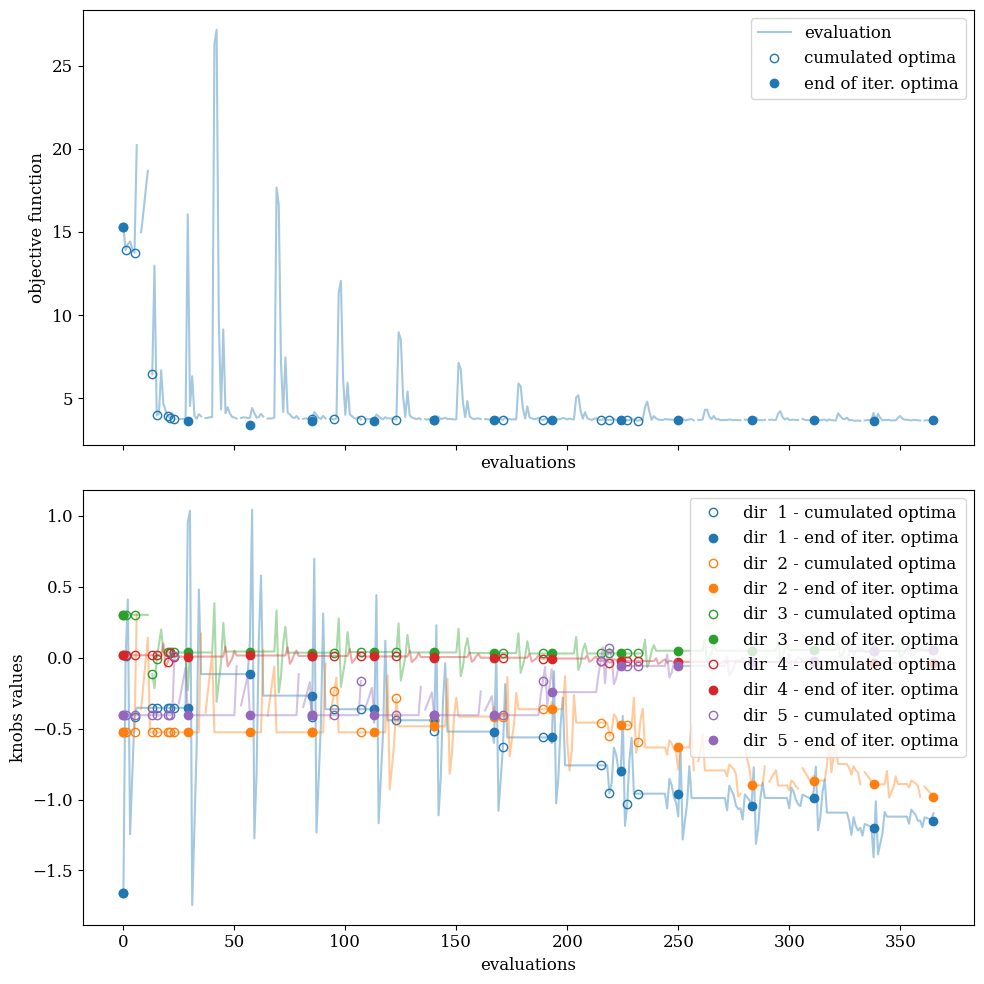

In [8]:
opt.plot_history()
plt.show()

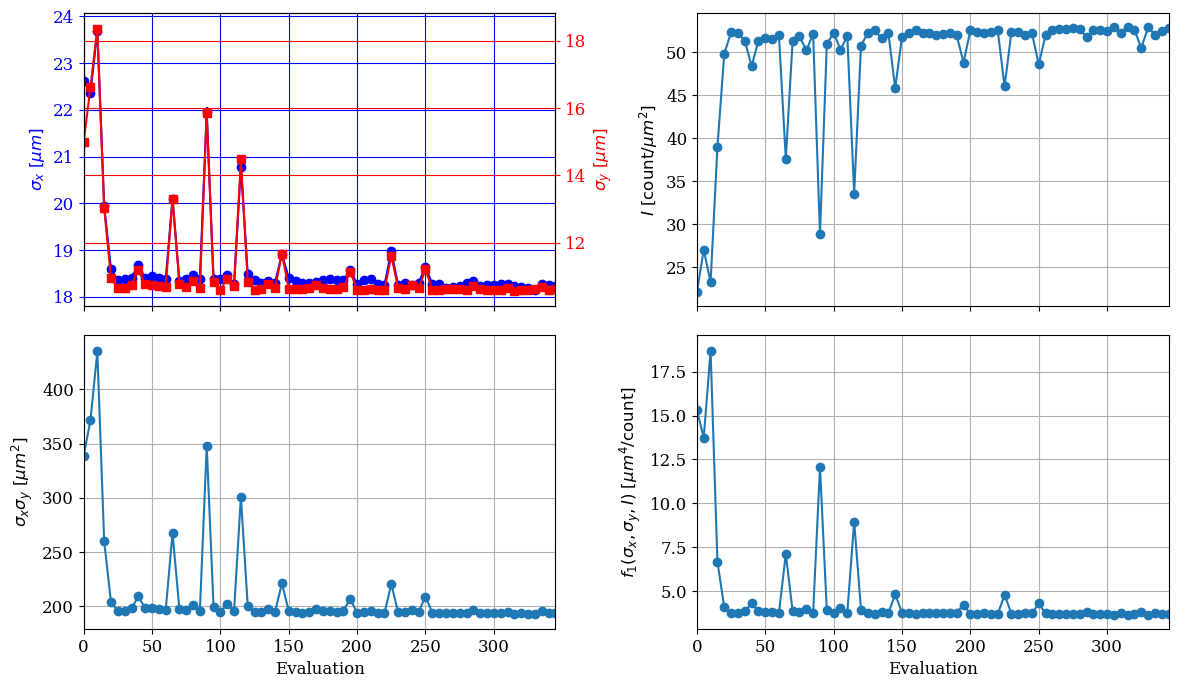

In [9]:
fig = plot_optimization_data(opt, k=5)
# save_figure(fig, "5D_observables", FIGURES_DIR)
plt.show()

In [10]:
display(pd.DataFrame([optimization_summary(opt, f1_grid)]))

,study,evaluations,initial objective,best objective,initial position,best position,f1 grid minimum
0,5D,366,15.297283,3.655138,"[-1.6574033314255026, -0.5263789868078006, 0.3...","[-1.1479505688483846, -0.980467147132176, 0.05...",3.633432


In [ ]:
paths = save_histories(opt, RUNS_DIR)
print("\n".join(str(path) for path in paths))

## Summary and (TX, RY) path over the `f1` map

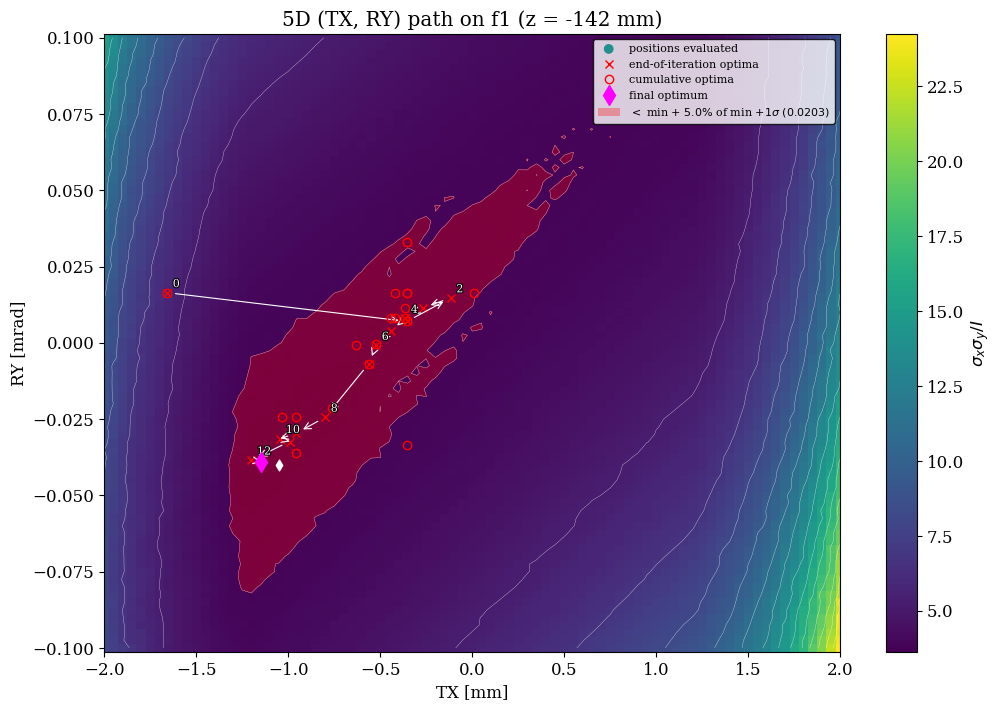

In [11]:
fig, ax = plot_knobspace_slice(opt, dir_idcs=(1, 4))
fig, ax = plot_single_objective(
    scan.zfocus, "f1", scan.tx, scan.ry,
    title=f"5D (TX, RY) path on f1 ({scan.focus_key})", fig=fig, ax=ax,
)
fig.set_size_inches(12, 8)
save_figure(fig, "5D_path_on_f1", FIGURES_DIR)
plt.show()

## Before / after beam fits

In [12]:
try:
    from shadow_interface.si_beamlines import CAXSim
except ImportError:
    from shadowpy.si_beamlines import CAXSim
from scripts.caustic import fit_beam_image

In [13]:
cax = CAXSim(total_rays=100_000, image_size=(210, 280))
tx, ty, rx, ry, rz = opt.positions_evaluated[0]
cax.mirror.offset = [tx, ty, 0.0]
cax.mirror.tilt = [rx, ry, rz]
cax.trace()
ana0 = fit_beam_image(cax.dvf_B1.image)

tx, ty, rx, ry, rz = opt.positions_best[-1]
cax.mirror.offset = [tx, ty, 0.0]
cax.mirror.tilt = [rx, ry, rz]
cax.trace()
anaf = fit_beam_image(cax.dvf_B1.image)

for label, position, ana in (
    ("initial", opt.positions_evaluated[0], ana0),
    ("best", opt.positions_best[-1], anaf),
):
    print(f"{label} position: {position}")
    ana.fit(ana.compute_momenta())
    ana.print_stats(ana.hprm_fitting)

 Generated         5000  rays out of       100000
                  10000
                  15000
                  20000
                  25000
                  30000
                  35000
                  40000
                  45000
                  50000
                  55000
                  60000
                  65000
                  70000
                  75000
                  80000
                  85000
                  90000
                  95000
                 100000
 Exit from SOURCE
 Call to RESET
 Exit from RESET
 Call to SETSOUR
 Exit from SETSOUR
 Call to IMREF
 Exit from IMREF
 Call to OPTAXIS
 Exit from OPTAXIS
 Call to MSETUP
 Exit from MSETUP
 Call to RESTART
 Exit from RESTART
 Call to MIRROR
 MIRROR1: Warning: Empty element (no mirr.xx file)
 Call to SCREEN
 Exit from SCREEN
 Call to IMAGE
 Exit from IMAGE
 Call to DEALLOC
 Exit from DEALLOC
Traced through element 1: MASK_A1
 Call to RESET
 Exit from RESET
 Call to SETSOUR
 Exit from SETSOUR